# Baseline heuristics across combats

The same randomly generated seeds are used for every heuristic. The horizontal boxplots compare cumulative player HP lost by the end of each combat.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'sts2_env').exists():
    ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'sts2_env').exists())
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from collections import Counter
import numpy as np
from sts2_env.encounters.act1 import *
from sts2_env.encounters.act2 import *
from sts2_env.encounters.act3 import *
from sts2_env.heuristics import evaluate_heuristics

In [5]:
CHARACTER_ID = 'Ironclad'  # e.g. 'Silent', 'Defect', 'Necrobinder', 'Regent'
ENCOUNTER = setup_fuzzy_wurm_crawler_weak
NUMBER_OF_COMBATS = 1_000
SEED_GENERATOR_SEED = 20261102
MAX_STEPS = 1_000
HEURISTICS = {
    'Block first': 'block_first',
    'Attack first': 'attack_first',
    'Block without wasting': 'block_without_wasting',
}
seeds = np.random.default_rng(SEED_GENERATOR_SEED).integers(0, 2**31 - 1, size=NUMBER_OF_COMBATS, dtype=np.int64).tolist()
results = evaluate_heuristics(ENCOUNTER, seeds, HEURISTICS, character_id=CHARACTER_ID, max_steps=MAX_STEPS)
summary = {
    label: {
        'win_rate': np.mean([trace.won for trace in traces]),
        'mean_lost_hp': np.mean([trace.lost_health[-1] for trace in traces]),
    }
    for label, traces in results.items()
}
summary

{'Block first': {'win_rate': np.float64(1.0),
  'mean_lost_hp': np.float64(11.084)},
 'Attack first': {'win_rate': np.float64(1.0),
  'mean_lost_hp': np.float64(10.777)},
 'Block without wasting': {'win_rate': np.float64(1.0),
  'mean_lost_hp': np.float64(10.777)}}

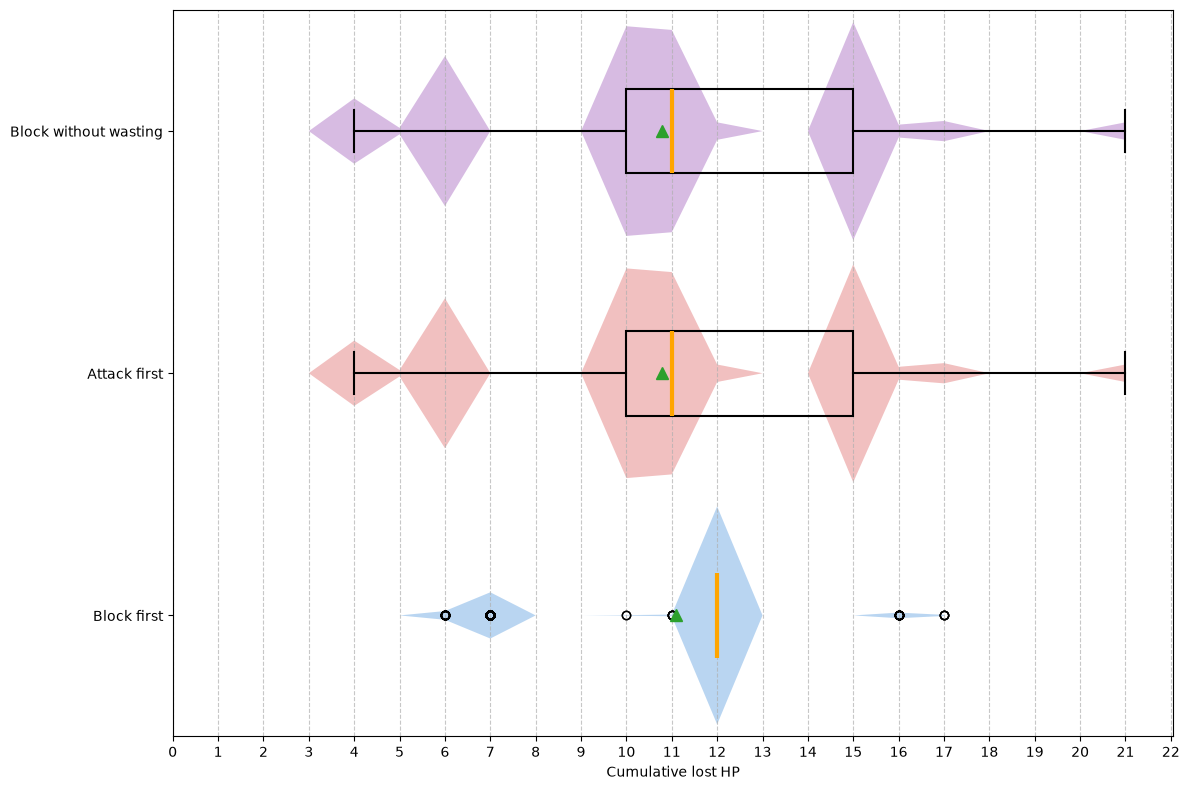

In [6]:
lost_health = {label: [trace.lost_health[-1] for trace in traces] for label, traces in results.items()}

data = list(lost_health.values())
labels = list(lost_health.keys())
positions = range(1, len(labels) + 1)
colors = ['#1976D2', '#D32F2F', '#7B1FA2'] 

fig, ax = plt.subplots(figsize=(12, 8))
# 1. Ręczne rysowanie ostrych "skrzypiec" z ciągłą interpolacją liniową
for i, (y_pos, strategy_data) in enumerate(zip(positions, data)):
    if not strategy_data:
        continue
        
    counts = Counter(strategy_data)
    min_val = min(strategy_data)
    max_val = max(strategy_data)
    
    # Tworzymy pełen zakres całkowitych wartości HP
    x_vals = np.arange(min(0, min_val), max_val + 1)
    y_counts = np.array([counts.get(x, 0) for x in x_vals])
    
    max_count = y_counts.max() if y_counts.max() > 0 else 1
    scaled_counts = (y_counts / max_count) * 0.45 
    
    # Rysujemy ostre linie
    ax.fill_between(
        x_vals, 
        y_pos - scaled_counts, 
        y_pos + scaled_counts, 
        facecolor=colors[i % len(colors)], 
        alpha=0.3
    )

# 2. Pełny, przezroczysty wykres pudełkowy na wierzchu
ax.boxplot(
    data,
    orientation='horizontal',
    showmeans=True,
    patch_artist=True,
    widths=0.35, 
    meanprops={'marker': '^', 'markerfacecolor': '#2ca02c', 'markeredgecolor': '#2ca02c', 'markersize': 8},
    medianprops={'color': 'orange', 'linewidth': 3},
    boxprops={'facecolor': 'none', 'edgecolor': 'black', 'linewidth': 1.5},
    whiskerprops={'color': 'black', 'linewidth': 1.5},
    capprops={'color': 'black', 'linewidth': 1.5}
)

ax.set_yticks(positions)
ax.set_yticklabels(labels)
ax.set_xlabel('Cumulative lost HP')

# Wymuszenie startu osi X od 0
ax.set_xlim(left=0)

# Wymuszenie podziałki co 1 punkt na osi X
ax.xaxis.set_major_locator(ticker.MultipleLocator(1))

# Gęsta pionowa siatka oparta na podziałce
ax.grid(axis='x', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()